# Global minimum-error allocation comparison

This notebook compares **Optimal**, **Greedy**, **Near-uniform**, and
**Random** fixed-budget sensor allocations. Every value is the actual
equal-prior PGM error computed from the output-state Gram matrix. Inputs use
unwrapped $\Delta_{ijm}=\pi(f_i(x_m)-f_j(x_m))$ values.

In [32]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
from IPython.display import display

NOTEBOOK_DIRECTORY = Path.cwd().resolve()
if not (NOTEBOOK_DIRECTORY / "comparison_analysis.py").exists():
    NOTEBOOK_DIRECTORY = NOTEBOOK_DIRECTORY / "min-error-global"
if str(NOTEBOOK_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIRECTORY))

import comparison_analysis
comparison_analysis = importlib.reload(comparison_analysis)

format_global_results_summary = comparison_analysis.format_global_results_summary
load_paired_results = comparison_analysis.load_paired_results
make_combined_comparison_plots = comparison_analysis.make_combined_comparison_plots
phase_range_summary = comparison_analysis.phase_range_summary
run_paired_dataset = comparison_analysis.run_paired_dataset
STATE_MODEL_LABELS = comparison_analysis.STATE_MODEL_LABELS

## Run settings

Set `RUN_ALL_CASES = False` for a reproducible 100-case test sample from each
compact dataset. Set it to `True` to evaluate every compact case. Each selected
case is evaluated for all three input-state models and every sensor budget from
$N=3$ through $N=12$.

In [33]:
DATASETS = ("compact_benchmark_1d", "compact_benchmark_2d")
RUN_ALL_CASES = True
TEST_CASES_PER_DATASET = 100
SENSOR_BUDGETS = tuple(range(3, 13))
SAMPLE_SEED = 20260827
RESULTS_ROOT = NOTEBOOK_DIRECTORY / "results" / "actual_pgm_four_methods_c_pi"

RUN_MODE = "full" if RUN_ALL_CASES else "test"
print("Run mode:", RUN_MODE)
print("Sensor budgets:", SENSOR_BUDGETS)
print("Results directory:", RESULTS_ROOT)

Run mode: full
Sensor budgets: (3, 4, 5, 6, 7, 8, 9, 10, 11, 12)
Results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-global/results/actual_pgm_four_methods_c_pi


## Evaluate allocations

The randomized baseline seeds are fixed by dataset, case, budget, and method.
Consequently, all three input-state models use the same Near-uniform and Random
allocations for a paired comparison.

In [34]:
records = []
for dataset in DATASETS:
    dataset_records = run_paired_dataset(
        dataset,
        sensor_budgets=SENSOR_BUDGETS,
        run_mode=RUN_MODE,
        test_case_count=TEST_CASES_PER_DATASET,
        sample_seed=SAMPLE_SEED,
        progress_every=10,
        results_root=RESULTS_ROOT,
    )
    records.extend(dataset_records)

print(f"Completed {len(records):,} paired state/budget runs.")

compact_benchmark_1d: completed 10/2520 cases
compact_benchmark_1d: completed 20/2520 cases
compact_benchmark_1d: completed 30/2520 cases
compact_benchmark_1d: completed 40/2520 cases
compact_benchmark_1d: completed 50/2520 cases
compact_benchmark_1d: completed 60/2520 cases
compact_benchmark_1d: completed 70/2520 cases
compact_benchmark_1d: completed 80/2520 cases
compact_benchmark_1d: completed 90/2520 cases
compact_benchmark_1d: completed 100/2520 cases
compact_benchmark_1d: completed 110/2520 cases
compact_benchmark_1d: completed 120/2520 cases
compact_benchmark_1d: completed 130/2520 cases
compact_benchmark_1d: completed 140/2520 cases
compact_benchmark_1d: completed 150/2520 cases
compact_benchmark_1d: completed 160/2520 cases
compact_benchmark_1d: completed 170/2520 cases
compact_benchmark_1d: completed 180/2520 cases
compact_benchmark_1d: completed 190/2520 cases
compact_benchmark_1d: completed 200/2520 cases
compact_benchmark_1d: completed 210/2520 cases
compact_benchmark_1d: 

## Comparison figures

The first three figures contain six panels: mean errors, gaps to Optimal, and
field-family gap distributions for the three input states in 1D and 2D. Two
figures compare input states separately for Greedy and Optimal. The final figure
shows paired runtime speedup
relative to Optimal in 1D and 2D box plots on a logarithmic axis. Figures are
saved as PNG and PDF.

Mean actual PGM errors across input states


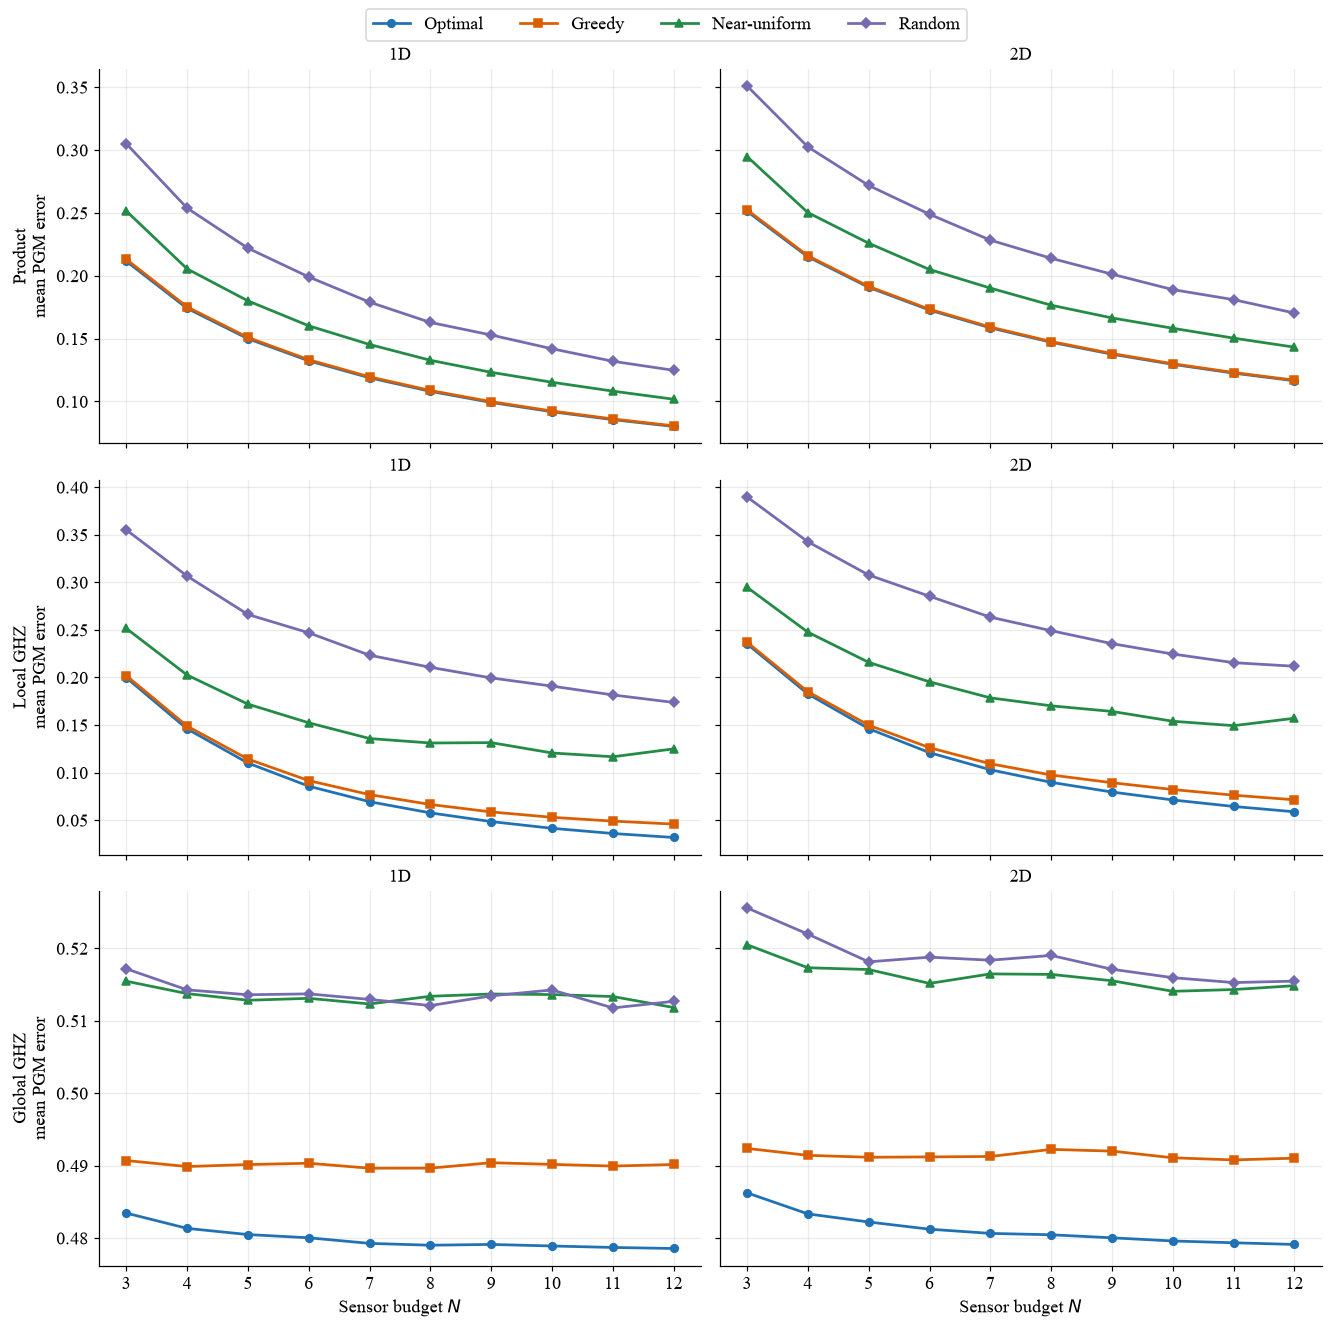

Mean actual PGM-error gaps


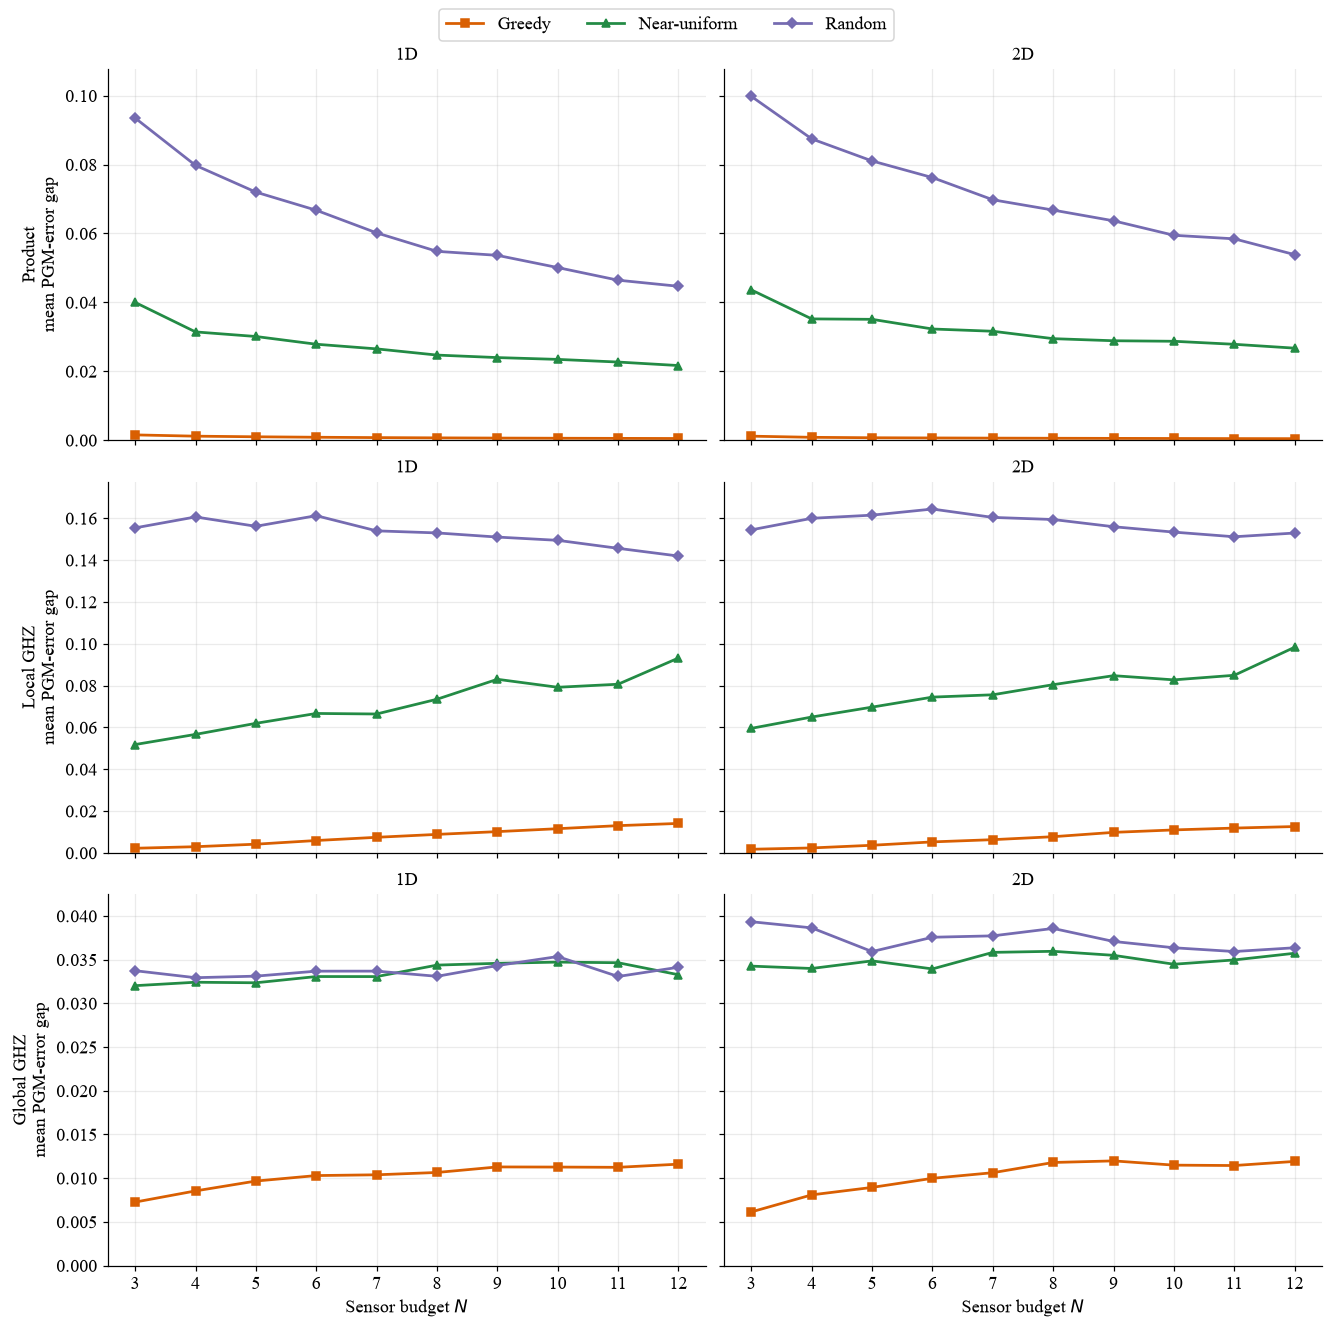

PGM-error gap by field family


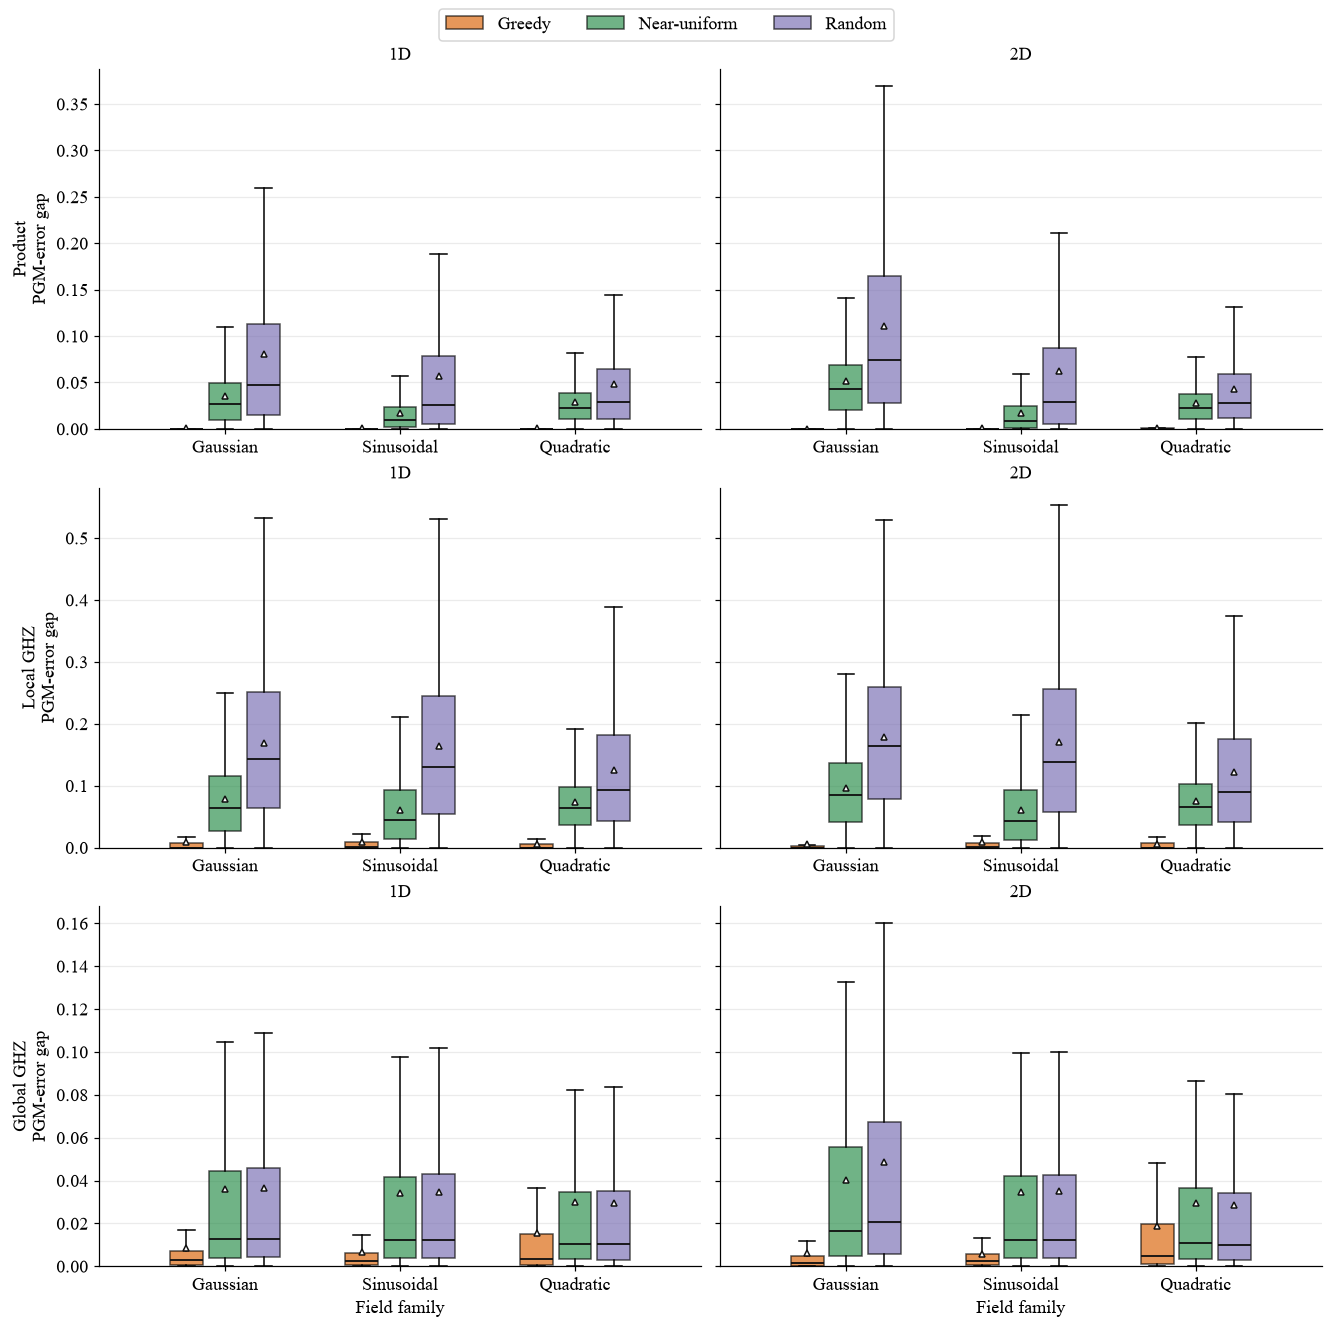

Greedy input-state comparison


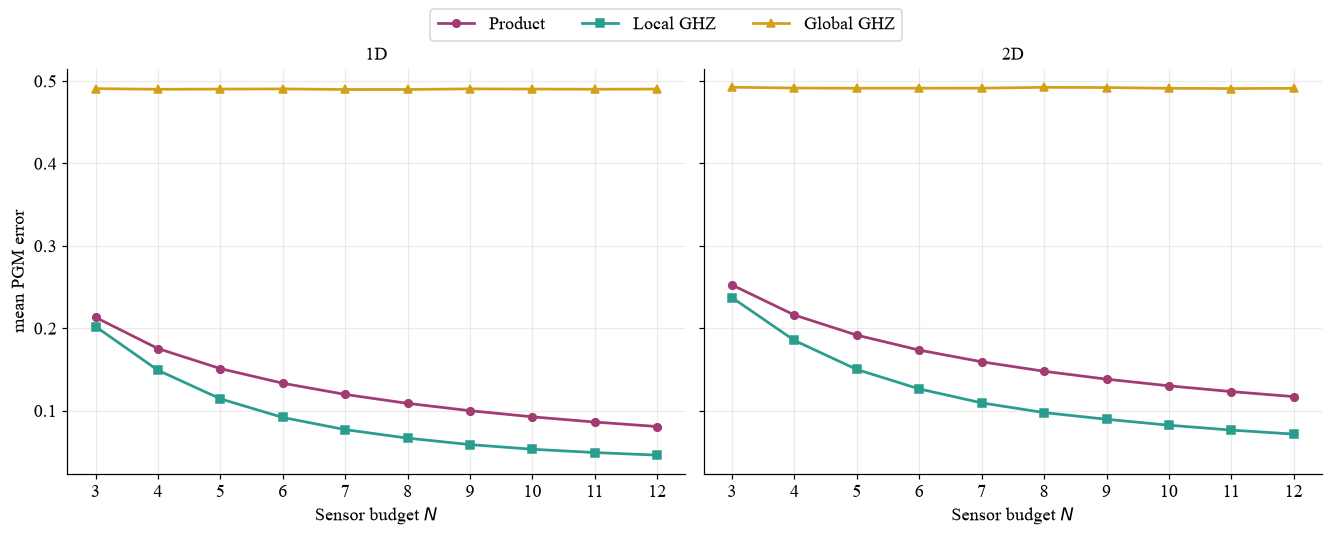

Optimal input-state comparison


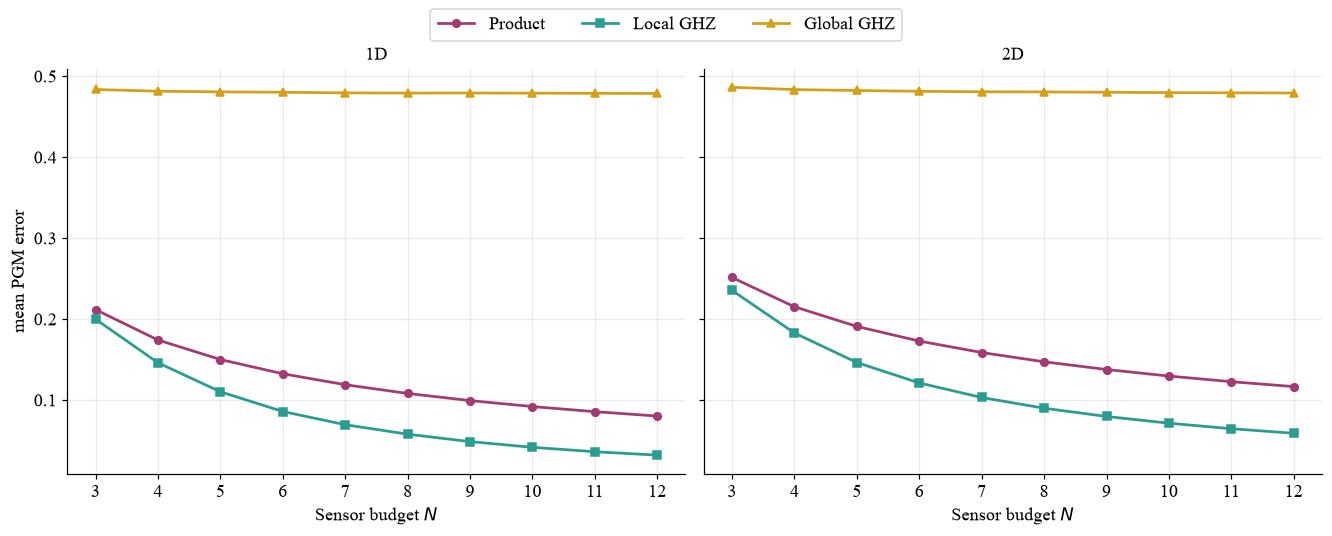

Runtime speedup relative to Optimal


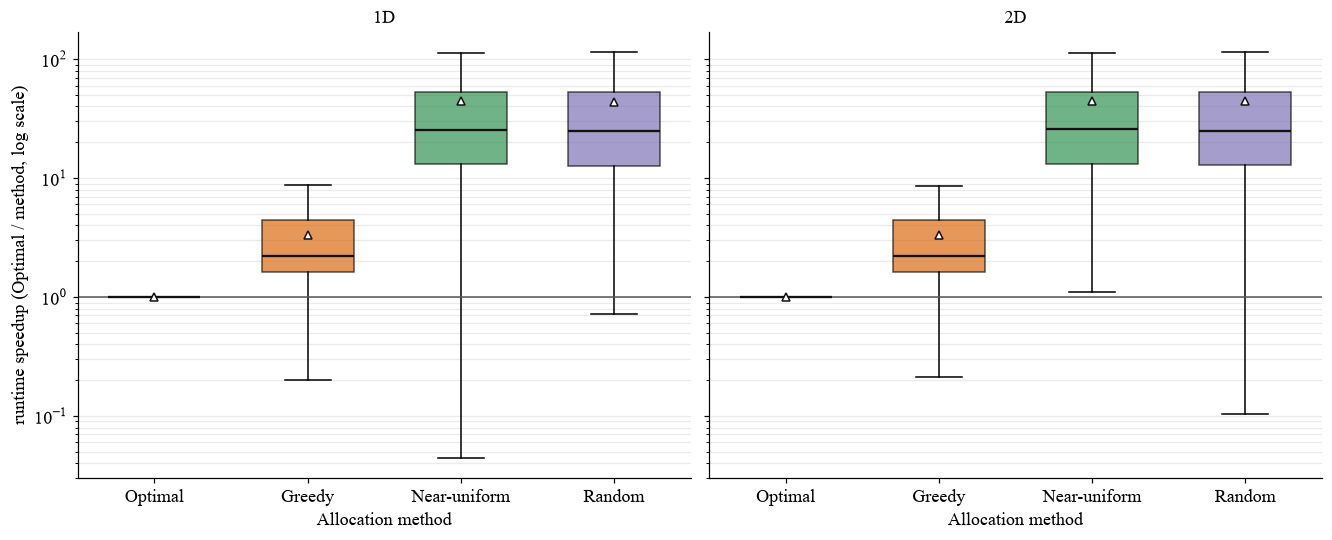

In [35]:
comparison_analysis = importlib.reload(comparison_analysis)
make_combined_comparison_plots = comparison_analysis.make_combined_comparison_plots

if not records:
    for dataset in DATASETS:
        records.extend(load_paired_results(dataset, results_root=RESULTS_ROOT))

FIGURE_DIRECTORY = RESULTS_ROOT / "figures"
figures = make_combined_comparison_plots(
    records,
    output_directory=FIGURE_DIRECTORY,
)
for title, figure in figures:
    print(title)
    display(figure)
    plt.close(figure)

## End-of-run numerical summary

This prints the compact optimality, baseline-reduction, sensor-budget,
field-family, and runtime statistics used in the results analysis.

In [ ]:
comparison_analysis = importlib.reload(comparison_analysis)
format_global_results_summary = comparison_analysis.format_global_results_summary
print(format_global_results_summary(records, compact=True))

In [37]:
phase_ranges = phase_range_summary(records)
print("Observed phase ranges")
for name, value in phase_ranges.items():
    print(f"{name}: {value}")
print("Saved figures:", FIGURE_DIRECTORY)

Observed phase ranges
cases: 5040
delta_min: -9.360406009168894
delta_max: 9.010336670802795
delta_abs_min: 2.0825197650078717e-25
delta_abs_max: 9.360406009168894
n_delta_min: -112.32487211002673
n_delta_max: 108.12404004963355
n_delta_abs_min: 6.247559295023616e-25
n_delta_abs_max: 112.32487211002673
Saved figures: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-global/results/actual_pgm_four_methods_c_pi/figures


## Paper figure recommendation

The compact benchmark supplies the exact Optimal reference and therefore has one
essential main-paper result.

**Include in the main paper:**

1. `mean_actual_pgm_error_gaps` — the direct approximation-quality comparison
   against exhaustive Optimal for all three input states and both dimensions.
2. `pgm_error_gap_by_field_family` — the Gaussian, sinusoidal, and quadratic
   sensitivity comparison, consistent with the other two allocation problems.

**Include only if runtime is part of the main claim:**

3. `runtime_boxplots` — paired runtime speedup relative to Optimal.

Place `mean_actual_pgm_errors` in supplementary material for absolute-error
context. The separate Greedy and Optimal input-state figures repeat information
already visible in the six-panel plots and do not need paper space.